# Logger session: head orientation, pose tracking, robot interaction, spikes
One wireless-logger session (rat on a round table with a walking robot, 6 cameras, IMU on the head-mounted logger, Intan512 ephys).
Everything here is loaded from analytics; the notebook only plots and runs the tuning analyses.

| analytic | what | computed with |
|---|---|---|
| `HeadOrientation` | IMU head angles, 100 Hz, drift-corrected, anatomical names | `python run_pipeline.py HeadOrientation --session_names <s>` (any env) |
| `BehaviorPose` | raw DLC keypoints on cam2, 30 Hz | DEEPLABCUT env, GPU: `python run_pipeline.py BehaviorPose --session_names <s>` |
| `ArenaPoseFeatures` | smoothed keypoints, rat + robot position, IMU angles per frame, robot bearing, turns | `python run_pipeline.py ArenaPoseFeatures --session_names <s>` (needs the two above) |
| `Spikes`, `SpikeClusterMetadata` | curated JRClust spikes with reliability flags | `python run_pipeline.py Spikes-SpikeClusterMetadata --session_names <s>` |

Sections: 1 what is what · 2 head orientation · 3 how certain the pose tracking is · 4 behaviour and attention to the robot ·
5 the session video · 6 spikes · 7 head-direction tuning · 8 snout-elevation tuning

In [1]:
import os
import sys

# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

In [2]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
import analytics_processing.sessions_from_nas_parsing as sp
from CustomLogger import CustomLogger as Logger

Logger().init_logger(None, None, logging_level="WARNING")
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

In [3]:
SESSION = '2026-09-09_15-15_rPG007_P1500_RobotInteract_45min'
F = sp.sessionnames2fullfnames([SESSION])[0][0]

data = {}
for analytic in ['HeadOrientation', 'ArenaPoseFeatures', 'Spikes', 'SpikeClusterMetadata', 'LoggerMalfunction']:
    data[analytic] = analytics.get_analytics(analytic, session_names=[SESSION]).reset_index(drop=True)

head, pose = data['HeadOrientation'], data['ArenaPoseFeatures']
spikes, units = data['Spikes'], data['SpikeClusterMetadata']
t_head = head.ephys_timestamp.values / 1e6          # s, ephys clock (all tables share it)
t_pose = pose.image_ephys_timestamp.values / 1e6
malf = data['LoggerMalfunction'].set_index('kind')
MAL = tuple(malf.loc['logger_window', ['start_ephys_timestamp', 'end_ephys_timestamp']] / 1e6)          # s
EXCLUDE = tuple(malf.loc['malfunction_period', ['start_ephys_timestamp', 'end_ephys_timestamp']] / 1e6)  # window + rate burst

def shade(ax):
    """logger malfunction window"""
    ax.axvspan(*MAL, color='crimson', alpha=.15, lw=0)

for k, v in data.items():
    print(f'{k:22s} {v.shape}')
print('pose model:', pose.dlc_scorer.iloc[0])

HeadOrientation        (275263, 13)
ArenaPoseFeatures      (81000, 81)
Spikes                 (4365818, 15)
SpikeClusterMetadata   (186, 26)
LoggerMalfunction      (108, 7)
pose model: DLC_Resnet50_ratArenaLoggerOct28shuffle6_snapshot_1300


In [4]:
data['Spikes']

,sample_id,ephys_timestamp,cluster_id_ssbatch,channel,amplitude_uV,ss_batch_id,channel_2nd,channel_3rd,shank,depth,cluster_id,cluster_id_str,cluster_color,gross_brain_area,fine_brain_area
0,4,200,13,440,-172.575,0,442,-1,2.0,1871.2073,13,Unit0013,#B2828D,shank2,shank2
1,35,1750,86,317,-100.425,0,300,-1,4.0,5343.6808,81,Unit0081,#511CFB,shank4,shank4
2,36,1800,18,442,-132.600,0,423,-1,2.0,1681.4641,18,Unit0018,#620042,shank2,shank2
3,62,3100,513,47,-120.900,0,51,-1,8.0,4492.3236,165,Unit0165,#6C4516,shank8,shank8
4,93,4650,24,444,-248.040,0,421,-1,2.0,1492.2906,24,Unit0024,#2E91E5,shank2,shank2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4365813,55052290,2752614500,30,445,-156.780,0,447,-1,2.0,928.2329,30,Unit0030,#B68100,shank2,shank2
4365814,55052330,2752616500,17,423,-108.030,0,421,-1,2.0,1779.2073,17,Unit0017,#A777F1,shank2,shank2
4365815,55052415,2752620750,30,445,-126.945,0,423,-1,2.0,928.2329,30,Unit0030,#B68100,shank2,shank2
4365816,55052451,2752622550,369,194,-124.020,0,189,-1,6.0,395.3849,139,Unit0139,#1616A7,shank6,shank6


## 1. What is what: sensors, axes and columns
**IMU (on the logger, 100 Hz).** The logger sits on the head turned by 90°: logger **x = left ear, y = towards the tail
(snout = -y), z = crown**. `HeadOrientation` already translates this into anatomical angles, so the raw `orientation_*` columns of the
session file are not needed (and the 9-axis `orientation_yaw/pitch/roll` should never be used: its magnetometer is mis-oriented).

| column (`HeadOrientation`, also per frame in `ArenaPoseFeatures`) | meaning | + means | trust |
|---|---|---|---|
| `head_direction` | horizontal direction of the snout in the **cam2 image frame**: 0° = image right, 90° = away from cam2 | turning left | gyro yaw corrected against the magnetometer every 10 s; ±10° vs video, no trend |
| `snout_elevation` | snout above the horizon | nose up | gravity-anchored, no drift |
| `head_tilt` | ear-to-ear line vs the horizon | right ear down | gravity-anchored, no drift |
| `clean` (`imu_clean`) | not within 100 ms of a data-loss pad and not in the logger malfunction window | | use it to select samples |

**Camera (cam2, 30 Hz, DLC).** 8 keypoints: `nose, left_ear, right_ear, logger_led, logger_back, tail_base, robot_front, robot_back`.
Positions are cam2 image px (x right, y down); distances and speeds are "floor px" (image y stretched by 1/0.69 to undo the oblique view).

| column (`ArenaPoseFeatures`) | meaning |
|---|---|
| `<kp>_x/_y/_likelihood` | raw DLC output |
| `<kp>_x_filt/_y_filt`, `<kp>_filt_std` | smoothed, short gaps filled (rat ≤ ~0.4 s, robot ≤ ~3 s), posterior std in px; NaN = not known |
| `head_x/_y` | the logger LED = rat head position (tracked in ~95 % of frames) |
| `movement_energy` | median speed of the tracked rat keypoints (floor px/s) |
| `robot_x/_y`, `robot_n_points`, `robot_inferred_age_s` | robot centre; 2 = both points tracked, 1 = inferred from one point, 0 = none |
| `robot_distance`, `robot_bearing` | head → robot distance; robot direction relative to the IMU head direction: 0° = ahead, ±180° = behind, + = left |
| `turn_towards_robot` | onset of a turn towards the robot (> 60° off for 1 s, then < 20° for 0.5 s) |
| `head_direction_dlc` | head direction from the DLC ear line, an independent check of the IMU one |

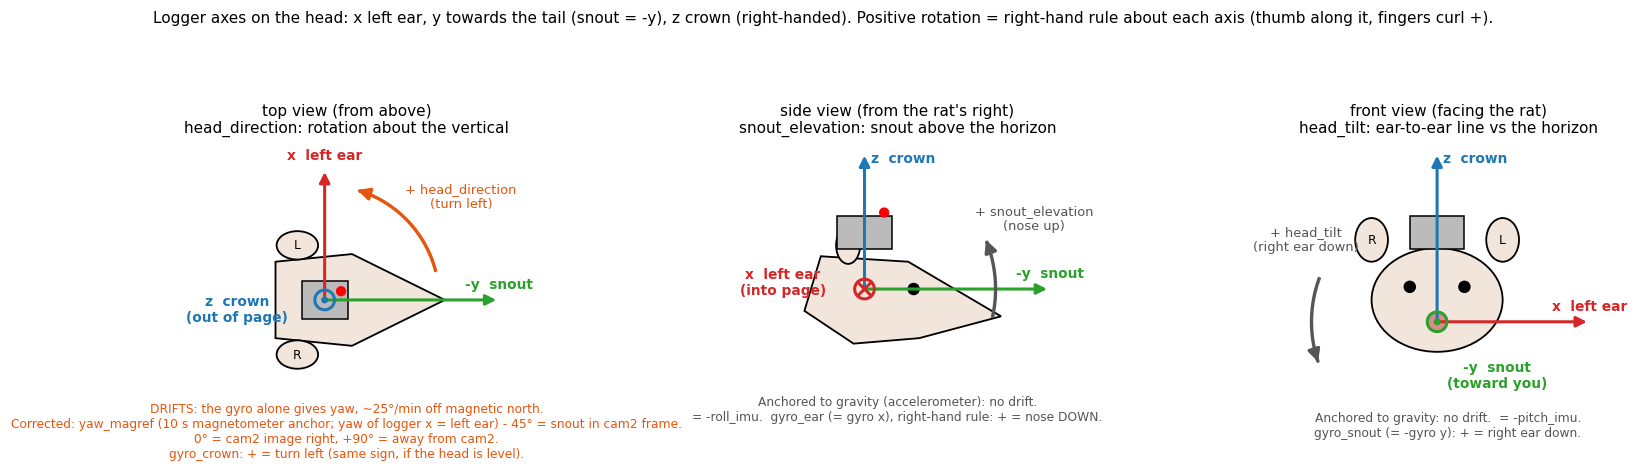

In [5]:
# head axes, positive rotation directions and the column names (drawn, not data)
from matplotlib.patches import Ellipse, Circle, Rectangle, FancyArrowPatch, Polygon

AX_COL = {'x': '#d62728', 'y': '#2ca02c', 'z': '#1f77b4'}
DRIFT, STABLE = '#e6550d', '#555555'

def ax_arrow(ax, p0, p1, col, label, off=(0, 0)):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=14, lw=2, color=col, zorder=5))
    ax.text(p1[0] + off[0], p1[1] + off[1], label, color=col, fontsize=9, ha='center', va='center', fontweight='bold')

def out_of_page(ax, p, col, label):
    ax.add_patch(Circle(p, .09, fill=False, ec=col, lw=2, zorder=5)); ax.add_patch(Circle(p, .025, color=col, zorder=5))
    ax.text(p[0] + .16, p[1] - .02, label, color=col, fontsize=9, va='center', fontweight='bold')

def into_page(ax, p, col, label):
    ax.add_patch(Circle(p, .09, fill=False, ec=col, lw=2, zorder=5))
    ax.plot([p[0] - .06, p[0] + .06], [p[1] - .06, p[1] + .06], color=col, lw=2, zorder=5)
    ax.plot([p[0] - .06, p[0] + .06], [p[1] + .06, p[1] - .06], color=col, lw=2, zorder=5)
    ax.text(p[0] + .16, p[1] - .02, label, color=col, fontsize=9, va='center', fontweight='bold')

def rot_arc(ax, c, r, a0, a1, col, text, txy):
    """Curved arrow from angle a0 to a1 (deg, counterclockwise on the page), = the + direction."""
    a = np.deg2rad(np.linspace(a0, a1, 40))
    ax.plot(c[0] + r * np.cos(a[:-3]), c[1] + r * np.sin(a[:-3]), color=col, lw=2.2, zorder=6)
    ax.add_patch(FancyArrowPatch((c[0] + r * np.cos(a[-4]), c[1] + r * np.sin(a[-4])),
                                 (c[0] + r * np.cos(a[-1]), c[1] + r * np.sin(a[-1])),
                                 arrowstyle='-|>', mutation_scale=16, color=col, lw=2.2, zorder=6))
    ax.text(*txy, text, color=col, fontsize=8.5, ha='center', va='center')

def logger(ax, xy, w, h):
    ax.add_patch(Rectangle((xy[0] - w / 2, xy[1] - h / 2), w, h, fc='#bbbbbb', ec='k', lw=1, zorder=3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax in axes:
    ax.set_aspect('equal'); ax.set_xlim(-1.6, 1.8); ax.set_ylim(-1.45, 1.45); ax.set_axis_off()
SKIN = dict(fc='#f2e6dc', ec='k', lw=1.2, zorder=2)

# top view: from above, snout to the right; the rat's left is up on the page
ax = axes[0]
ax.add_patch(Polygon([(1.0, 0), (.15, .42), (-.55, .35), (-.55, -.35), (.15, -.42)], closed=True, **SKIN))
ax.add_patch(Ellipse((-.35, .5), .38, .26, **SKIN)); ax.add_patch(Ellipse((-.35, -.5), .38, .26, **SKIN))
ax.text(-.35, .5, 'L', ha='center', va='center', fontsize=8); ax.text(-.35, -.5, 'R', ha='center', va='center', fontsize=8)
logger(ax, (-.1, 0), .42, .34); ax.add_patch(Circle((.05, .08), .04, color='red', zorder=4))
ax_arrow(ax, (-.1, 0), (1.5, 0), AX_COL['y'], '-y  snout', (0, .14))
ax_arrow(ax, (-.1, 0), (-.1, 1.2), AX_COL['x'], 'x  left ear', (0, .12))
out_of_page(ax, (-.1, 0), AX_COL['z'], '')
ax.text(-.9, -.2, 'z  crown\n(out of page)', color=AX_COL['z'], fontsize=9, fontweight='bold', ha='center')
rot_arc(ax, (-.1, 0), 1.05, 15, 75, DRIFT, '+ head_direction\n(turn left)', (1.15, .95))
ax.set_title('top view (from above)\nhead_direction: rotation about the vertical', fontsize=10)
ax.text(.1, -1.2, 'DRIFTS: the gyro alone gives yaw, ~25°/min off magnetic north.\n'
        'Corrected: yaw_magref (10 s magnetometer anchor; yaw of logger x = left ear) - 45° = snout in cam2 frame.\n'
        '0° = cam2 image right, +90° = away from cam2.\ngyro_crown: + = turn left (same sign, if the head is level).', color=DRIFT, fontsize=8, ha='center', va='center')

# side view: seen from the rat's right side, snout to the right; the left ear (y) points into the page
ax = axes[1]
ax.add_patch(Polygon([(1.05, -.15), (.2, .35), (-.6, .4), (-.75, -.1), (-.3, -.4), (.3, -.35)], closed=True, **SKIN))
ax.add_patch(Ellipse((-.35, .5), .22, .34, **SKIN)); ax.add_patch(Circle((.25, .1), .05, color='k', zorder=3))
logger(ax, (-.2, .62), .5, .3); ax.add_patch(Circle((-.02, .8), .04, color='red', zorder=4))
ax_arrow(ax, (-.2, .1), (1.5, .1), AX_COL['y'], '-y  snout', (0, .14))
ax_arrow(ax, (-.2, .1), (-.2, 1.35), AX_COL['z'], 'z  crown', (.35, -.05))
into_page(ax, (-.2, .1), AX_COL['x'], '')
ax.text(-.95, .05, 'x  left ear\n(into page)', color=AX_COL['x'], fontsize=9, fontweight='bold', ha='center')
rot_arc(ax, (-.2, .1), 1.2, -12, 22, STABLE, '+ snout_elevation\n(nose up)', (1.35, .75))
ax.set_title('side view (from the rat\'s right)\nsnout_elevation: snout above the horizon', fontsize=10)
ax.text(.1, -1.0, 'Anchored to gravity (accelerometer): no drift.\n= -roll_imu.  gyro_ear (= gyro x), right-hand rule: + = nose DOWN.',
        color=STABLE, fontsize=8, ha='center', va='center')

# front view: facing the rat, the snout points at you; its left ear appears on your right
ax = axes[2]
ax.add_patch(Ellipse((0, 0), 1.2, .95, **SKIN))
ax.add_patch(Ellipse((.6, .55), .3, .4, **SKIN)); ax.add_patch(Ellipse((-.6, .55), .3, .4, **SKIN))
ax.text(.6, .55, 'L', ha='center', va='center', fontsize=8); ax.text(-.6, .55, 'R', ha='center', va='center', fontsize=8)
ax.add_patch(Circle((.25, .12), .05, color='k', zorder=3)); ax.add_patch(Circle((-.25, .12), .05, color='k', zorder=3))
ax.add_patch(Circle((0, -.2), .08, color='#d98c8c', zorder=3))
logger(ax, (0, .62), .5, .3)
ax_arrow(ax, (0, -.2), (1.4, -.2), AX_COL['x'], 'x  left ear', (0, .14))
ax_arrow(ax, (0, -.2), (0, 1.35), AX_COL['z'], 'z  crown', (.35, -.05))
out_of_page(ax, (0, -.2), AX_COL['y'], '')
ax.text(.55, -.8, '-y  snout\n(toward you)', color=AX_COL['y'], fontsize=9, fontweight='bold', ha='center')
rot_arc(ax, (0, -.2), 1.15, 160, 200, STABLE, '+ head_tilt\n(right ear down)', (-1.2, .55))
ax.set_title('front view (facing the rat)\nhead_tilt: ear-to-ear line vs the horizon', fontsize=10)
ax.text(.1, -1.15, 'Anchored to gravity: no drift.  = -pitch_imu.\ngyro_snout (= -gyro y): + = right ear down.',
        color=STABLE, fontsize=8, ha='center', va='center')

fig.suptitle('Logger axes on the head: x left ear, y towards the tail (snout = -y), z crown (right-handed). '
             'Positive rotation = right-hand rule about each axis (thumb along it, fingers curl +).', fontsize=10)
plt.tight_layout()

## 2. Head orientation (IMU)
The three angles over the whole session. Shaded red: logger malfunction window; grey dots: samples that are not `clean`.

clean samples: 99.1%


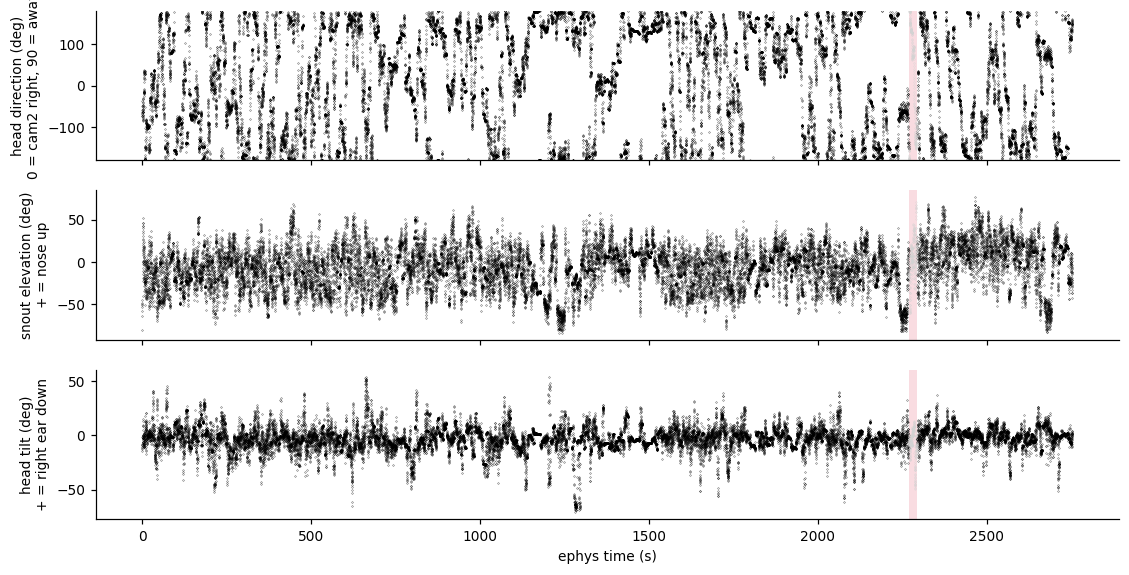

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
sub = slice(None, None, 10)
for ax, col, lab in zip(axes, ['head_direction', 'snout_elevation', 'head_tilt'],
                        ['head direction (deg)\n0 = cam2 right, 90 = away', 'snout elevation (deg)\n+ = nose up', 'head tilt (deg)\n+ = right ear down']):
    c = head.clean.values[sub]
    ax.plot(t_head[sub][c], head[col].values[sub][c], '.', ms=.4, color='k')
    ax.plot(t_head[sub][~c], head[col].values[sub][~c], '.', ms=.4, color='lightgrey')
    ax.set_ylabel(lab); shade(ax)
axes[0].set_ylim(-180, 180); axes[-1].set_xlabel('ephys time (s)')
print(f"clean samples: {head.clean.mean():.1%}")

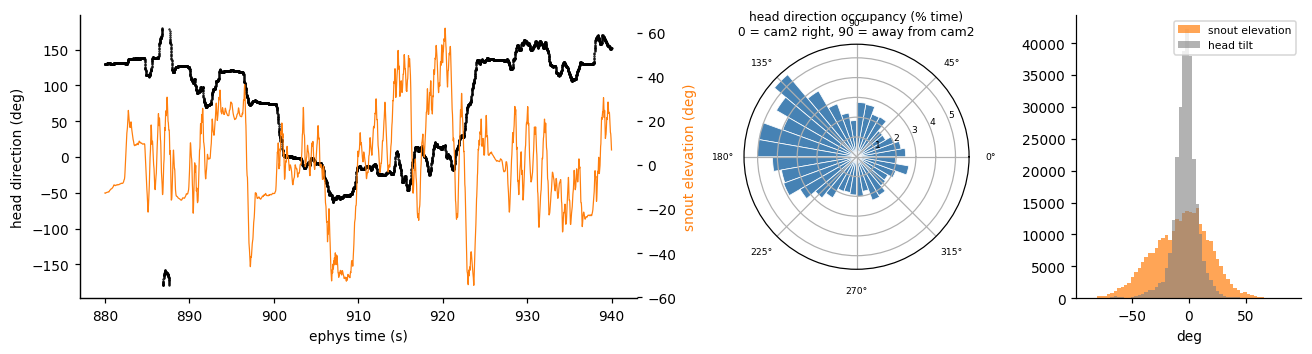

In [7]:
# a 60 s zoom, and how the head is oriented over the session
t0 = 880
w = (t_head >= t0) & (t_head < t0 + 60)
fig = plt.figure(figsize=(12, 3.3))
ax = fig.add_subplot(1, 4, (1, 2))
ax.plot(t_head[w], head.head_direction.values[w], '.', ms=1, color='k', label='head_direction')
ax2 = ax.twinx(); ax2.plot(t_head[w], head.snout_elevation.values[w], color='C1', lw=.8, label='snout_elevation')
ax.set_ylabel('head direction (deg)'); ax2.set_ylabel('snout elevation (deg)', color='C1'); ax.set_xlabel('ephys time (s)')
ax = fig.add_subplot(1, 4, 3, projection='polar')
h, e = np.histogram(np.deg2rad(head.head_direction[head.clean]), bins=36, range=(-np.pi, np.pi))
ax.bar(e[:-1], h / head.clean.sum() * 100, width=np.diff(e), align='edge', color='steelblue', edgecolor='white', lw=.5)
ax.set_title('head direction occupancy (% time)\n0 = cam2 right, 90 = away from cam2', fontsize=8); ax.tick_params(labelsize=6)
ax = fig.add_subplot(1, 4, 4)
ax.hist(head.snout_elevation[head.clean], bins=np.arange(-90, 91, 3), color='C1', alpha=.7, label='snout elevation')
ax.hist(head.head_tilt[head.clean], bins=np.arange(-90, 91, 3), color='grey', alpha=.6, label='head tilt')
ax.set_xlabel('deg'); ax.legend(fontsize=7)
plt.tight_layout()

## 3. Pose tracking: how certain is each point?
A keypoint is **tracked** when DLC's likelihood is ≥ 0.6. Short gaps are **filled** by a Kalman smoother whose own uncertainty decides
how long a gap it bridges; everything else is **missing**. Top: tracked fraction per second. Bottom left: tracked / filled / missing
per keypoint. Bottom right: the missing time split by the length of the gap it is in (only short gaps can ever be filled).

,nose,left_ear,right_ear,logger_led,logger_back,tail_base,robot_front,robot_back
tracked,0.19,0.75,0.49,0.93,0.79,0.59,0.37,0.83
filled,0.11,0.11,0.13,0.03,0.12,0.10,0.25,0.08
missing,0.71,0.14,0.38,0.05,0.10,0.31,0.38,0.09


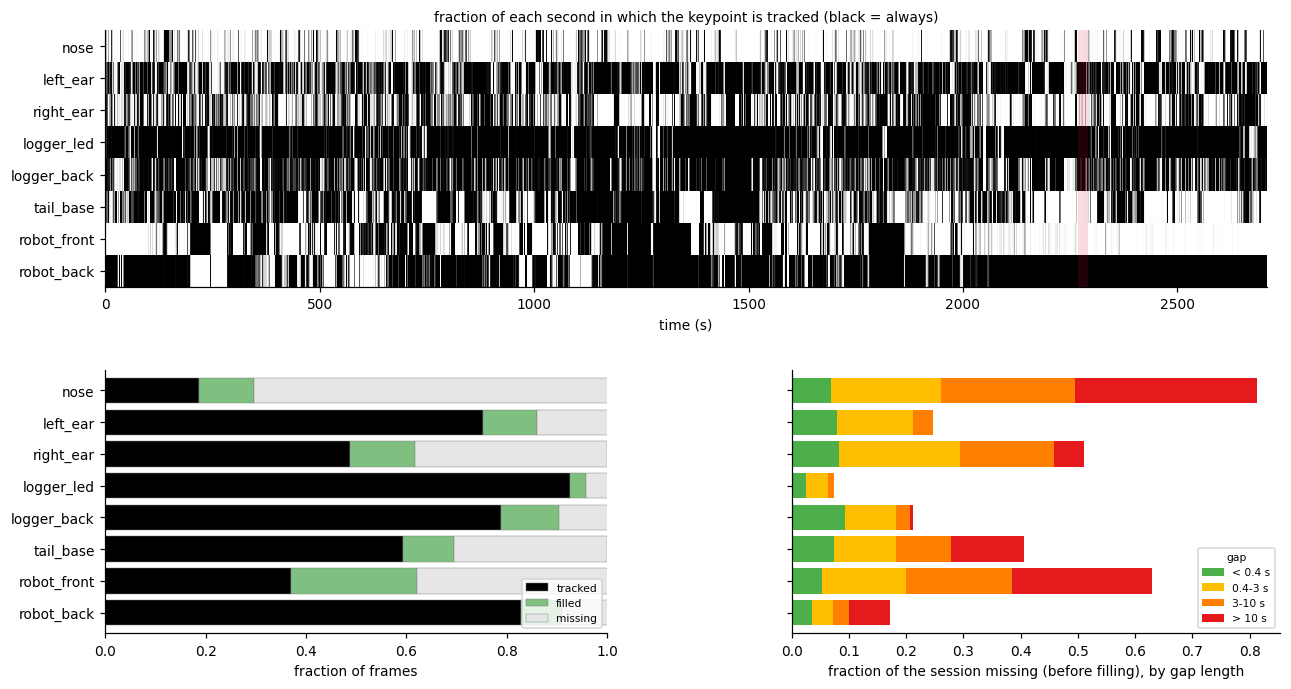

In [8]:
KP = ['nose', 'left_ear', 'right_ear', 'logger_led', 'logger_back', 'tail_base', 'robot_front', 'robot_back']
tracked = pd.DataFrame({k: pose[f'{k}_likelihood'].values >= C.DLC_MIN_LIKELIHOOD for k in KP})
known = pd.DataFrame({k: pose[f'{k}_x_filt'].notna().values for k in KP})
raster = tracked.groupby((t_pose - t_pose[0]).astype(int)).mean().T

def gap_frames(ok):
    miss = pd.Series(~np.asarray(ok))
    g = miss.groupby((~miss).cumsum()).sum()
    return g[g > 0].values
GAPS = [(0, .4, '< 0.4 s'), (.4, 3, '0.4-3 s'), (3, 10, '3-10 s'), (10, np.inf, '> 10 s')]
gap_split = pd.DataFrame({k: [(g := gap_frames(tracked[k]))[(g >= lo * 30) & (g < hi * 30)].sum() / len(pose) for lo, hi, _ in GAPS]
                          for k in KP}, index=[lab for *_, lab in GAPS]).T
status = pd.DataFrame({'tracked': tracked.mean(), 'filled': (known & ~tracked).mean(), 'missing': (~known).mean()})

fig = plt.figure(figsize=(12, 6.3))
ax = fig.add_axes([.08, .58, .88, .37])
ax.imshow(raster.values, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest', extent=(0, raster.shape[1], len(KP) - .5, -.5))
ax.set_yticks(range(len(KP))); ax.set_yticklabels(KP); ax.set_xlabel('time (s)'); shade(ax)
ax.set_title('fraction of each second in which the keypoint is tracked (black = always)', fontsize=9)
ax = fig.add_axes([.08, .08, .38, .38])
status.plot.barh(stacked=True, ax=ax, color=['k', '#7fbf7f', '#e6e6e6'], width=.8, edgecolor='grey', lw=.3)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('fraction of frames'); ax.legend(fontsize=7, loc='lower right')
ax = fig.add_axes([.6, .08, .37, .38])
gap_split.plot.barh(stacked=True, ax=ax, color=['#4daf4a', '#ffbf00', '#ff7f00', '#e41a1c'], width=.8)
ax.invert_yaxis(); ax.set_yticklabels([]); ax.set_xlabel('fraction of the session missing (before filling), by gap length')
ax.legend(fontsize=7, title='gap', title_fontsize=7)
status.round(2).T

**Robot.** The robot centre needs both points; when only one is tracked, the other is inferred from the robot's front-back vector of
the nearest frames with both (the robot turns slowly, median 2°/s). Left: how the centre is known over the session (per minute).
Right: for inferred frames, how far away the nearest two-point frame is: the longer, the less certain the centre (~40 px at 10 s).

{'both': 0.555, 'inferred': 0.414, 'none': 0.031} | inferred within 10 s of a two-point frame: 90%


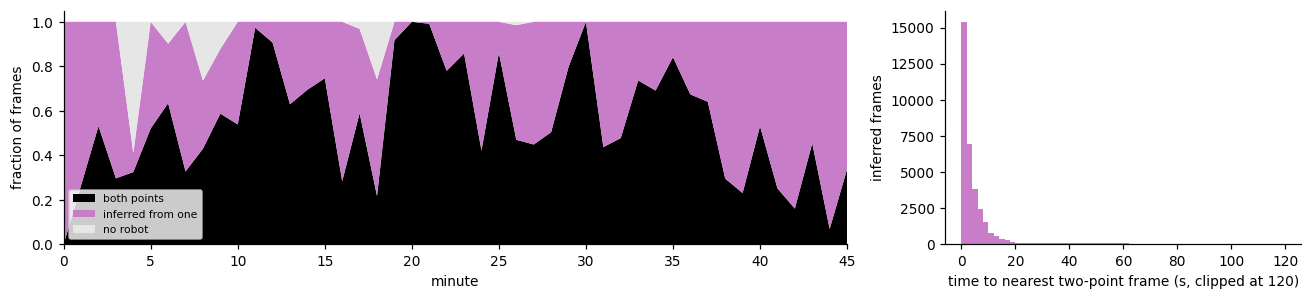

In [9]:
minute = ((t_pose - t_pose[0]) // 60).astype(int)
src = pd.crosstab(minute, pose.robot_n_points, normalize='index').reindex(columns=[2, 1, 0], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), gridspec_kw={'width_ratios': [2.2, 1]})
axes[0].stackplot(src.index, src.T.values, colors=['k', '#c77dc7', '#e6e6e6'], labels=['both points', 'inferred from one', 'no robot'])
axes[0].set_xlabel('minute'); axes[0].set_ylabel('fraction of frames'); axes[0].legend(fontsize=7, loc='lower left'); axes[0].set_xlim(0, minute.max())
age = pose.robot_inferred_age_s.dropna()
axes[1].hist(np.clip(age, 0, 120), bins=np.arange(0, 121, 2), color='#c77dc7')
axes[1].set_xlabel('time to nearest two-point frame (s, clipped at 120)'); axes[1].set_ylabel('inferred frames')
plt.tight_layout()
print(pose.robot_n_points.value_counts(normalize=True).rename({2: 'both', 1: 'inferred', 0: 'none'}).round(3).to_dict(),
      f'| inferred within 10 s of a two-point frame: {(age < 10).mean():.0%}')

**Independent check: camera vs IMU head direction.** Where both ears are known, the ear line gives a head direction that does not
drift. It should agree with the IMU `head_direction` without a constant offset (that would mean the cam2 offset is wrong) and without
a trend over the session (that would mean the drift correction is wrong).

camera head direction available in 51% of frames; within 30 deg of the IMU: 86%


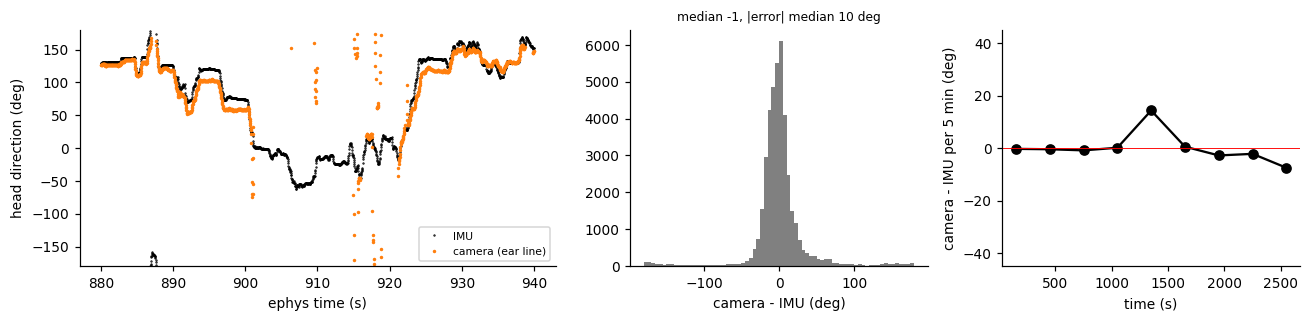

In [10]:
wrap = lambda d: (d + 180) % 360 - 180
ok = pose.head_direction_dlc.notna().values & pose.imu_clean.values
diff = wrap(pose.head_direction_dlc.values - pose.head_direction.values)[ok]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), gridspec_kw={'width_ratios': [1.6, 1, 1]})
w = ok & (t_pose >= 880) & (t_pose < 940)
win = (t_pose >= 880) & (t_pose < 940)
axes[0].plot(t_pose[win], pose.head_direction.values[win], '.', ms=1, color='k', label='IMU')
axes[0].plot(t_pose[w], pose.head_direction_dlc.values[w], '.', ms=2.5, color='C1', label='camera (ear line)')
axes[0].set_ylim(-180, 180); axes[0].set_xlabel('ephys time (s)'); axes[0].set_ylabel('head direction (deg)'); axes[0].legend(fontsize=7)
axes[1].hist(diff, bins=np.arange(-180, 181, 5), color='grey'); axes[1].set_xlabel('camera - IMU (deg)')
axes[1].set_title(f'median {np.median(diff):+.0f}, |error| median {np.median(np.abs(diff)):.0f} deg', fontsize=8)
blk = pd.DataFrame({'z': np.exp(1j * np.deg2rad(diff)), 'b': (t_pose[ok] // 300).astype(int)}).groupby('b').z.agg(['mean', 'size'])
blk = blk[blk['size'] >= 300]
axes[2].plot(blk.index * 300 + 150, np.rad2deg(np.angle(blk['mean'])), 'o-', color='k'); axes[2].axhline(0, color='r', lw=.6)
axes[2].set_ylim(-45, 45); axes[2].set_xlabel('time (s)'); axes[2].set_ylabel('camera - IMU per 5 min (deg)')
plt.tight_layout()
print(f'camera head direction available in {ok.mean():.0%} of frames; within 30 deg of the IMU: {np.mean(np.abs(diff) < 30):.0%}')

## 4. Behaviour: where, how much, and attention to the robot
The arena seen from above (as from cam2, cam2 at the bottom), one panel per 5 minutes: the rat's head (logger LED) coloured by time
within the panel, the robot centre in grey, turns towards the robot as red rings with a line to the robot. Heads above the wall are
drawn on the rim. The floor outline is fitted from the video (`render_logger_arena_video.fit_arena_ellipse`).

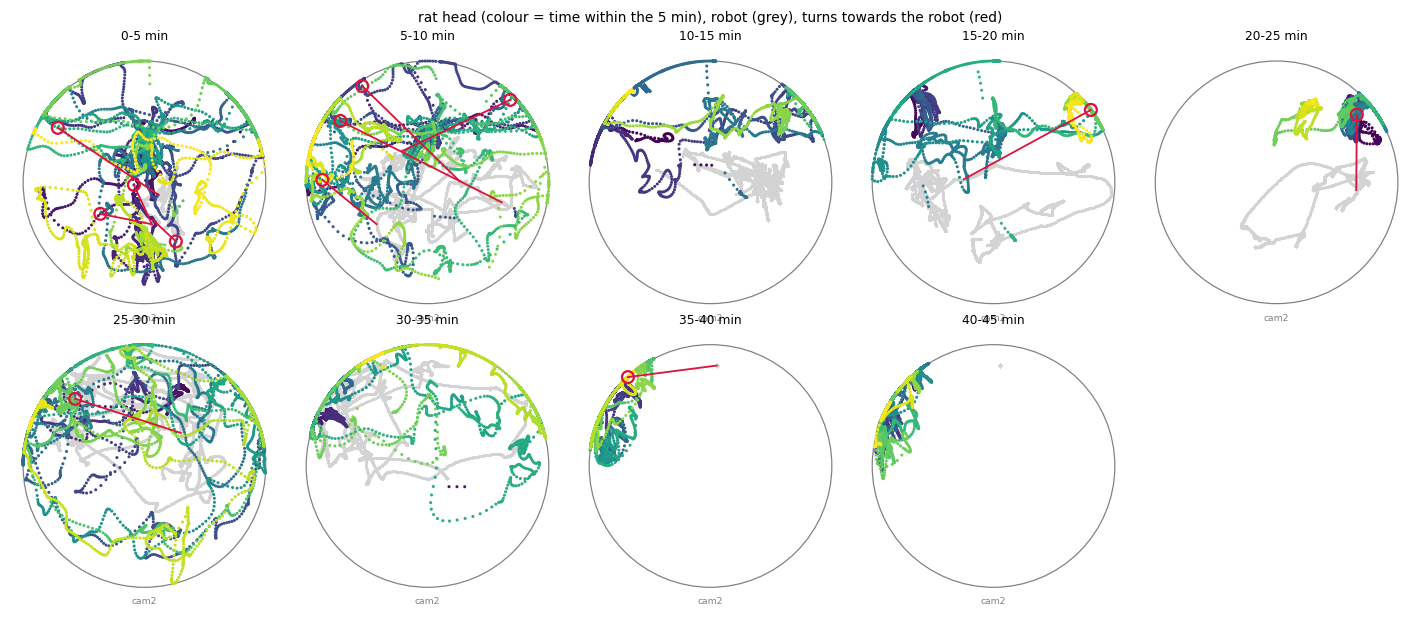

In [11]:
from render_logger_arena_video import fit_arena_ellipse
video = os.path.join(os.path.dirname(F), 'rendered_videos', 'cam2.mp4')
ellipse_cache = os.path.join(os.path.dirname(F), 'rendered_videos', 'cam2_arena', 'arena_ellipse_cam2.npy')
os.makedirs(os.path.dirname(ellipse_cache), exist_ok=True)
ecx, ecy, ew, eh, _ = fit_arena_ellipse(video, ellipse_cache)
ea, eb = max(ew, eh) / 2, min(ew, eh) / 2

def to_top(x, y):
    """cam2 image px -> top view (unit circle, cam2 at the bottom); points beyond the floor edge go onto the rim"""
    u, v = (np.asarray(x) - ecx) / ea, -(np.asarray(y) - ecy) / eb
    r = np.maximum(np.hypot(u, v), 1)
    return u / r, v / r

turns = np.flatnonzero(pose.turn_towards_robot.values)
SLICE = 9000                                                 # 5 min of frames
n_slices = int(np.ceil(len(pose) / SLICE))
fig, axes = plt.subplots(2, (n_slices + 1) // 2, figsize=(13, 5.6))
for i, ax in enumerate(axes.ravel()):
    ax.set_aspect('equal'); ax.set_axis_off()
    if i >= n_slices:
        continue
    s = slice(i * SLICE, min((i + 1) * SLICE, len(pose)))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='grey', lw=.8))
    ax.scatter(*to_top(pose.robot_x.values[s], pose.robot_y.values[s]), s=1, color='lightgrey')
    ax.scatter(*to_top(pose.head_x.values[s], pose.head_y.values[s]), s=1, c=np.arange(s.stop - s.start), cmap='viridis')
    for k in turns[(turns >= s.start) & (turns < s.stop)]:
        (hx, hy), (rx, ry) = to_top(pose.head_x.values[k], pose.head_y.values[k]), to_top(pose.robot_x.values[k], pose.robot_y.values[k])
        ax.plot([hx, rx], [hy, ry], color='crimson', lw=1.2); ax.scatter(hx, hy, s=60, facecolor='none', edgecolor='crimson', lw=1.5)
    ax.set_title(f'{i * 5}-{min(i * 5 + 5, len(pose) / 30 / 60):.0f} min', fontsize=8); ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
    ax.text(0, -1.08, 'cam2', ha='center', va='top', fontsize=6, color='grey')
fig.suptitle('rat head (colour = time within the 5 min), robot (grey), turns towards the robot (red)', fontsize=9)
plt.tight_layout()

1 s bins: r(movement energy, |head turning|) = 0.70


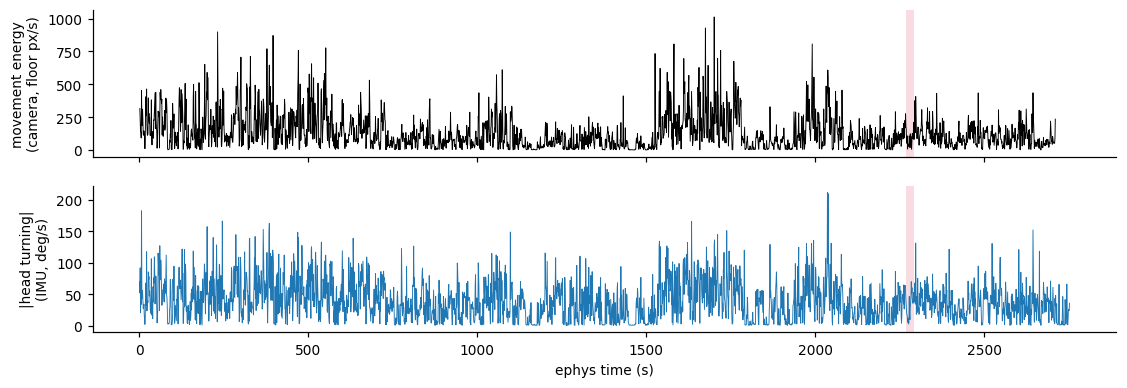

In [12]:
# how much the rat moves: camera (movement energy) and IMU (head angular speed), 1 s means
sec = (t_pose - t_pose[0]).astype(int)
energy_1s = pd.Series(pose.movement_energy.values).groupby(sec).mean()
turn_1s = pd.Series(np.abs(head.head_direction_vel.values)).groupby((t_head - t_pose[0]).astype(int)).mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 3.8), sharex=True)
axes[0].plot(energy_1s.index + t_pose[0], energy_1s.values, color='k', lw=.6); axes[0].set_ylabel('movement energy\n(camera, floor px/s)')
axes[1].plot(turn_1s.index + t_pose[0], turn_1s.values, color='C0', lw=.6); axes[1].set_ylabel('|head turning|\n(IMU, deg/s)')
axes[1].set_xlabel('ephys time (s)')
for ax in axes:
    shade(ax)
common = energy_1s.index.intersection(turn_1s.index)
print(f'1 s bins: r(movement energy, |head turning|) = {np.corrcoef(energy_1s[common].fillna(0), turn_1s[common].fillna(0))[0, 1]:.2f}')

**Attention to the robot.** `robot_bearing`: where the robot is relative to where the head points (IMU), 0° = straight ahead.
Left: how often each bearing occurs (flat line = no preference). Middle: bearing against distance. Right: the turns towards the
robot, aligned to the turn: the bearing drops to ~0, then the distance shrinks if the rat approaches.

robot within 30 deg of the head direction in 7.8% of the frames with a robot bearing (92% of frames)


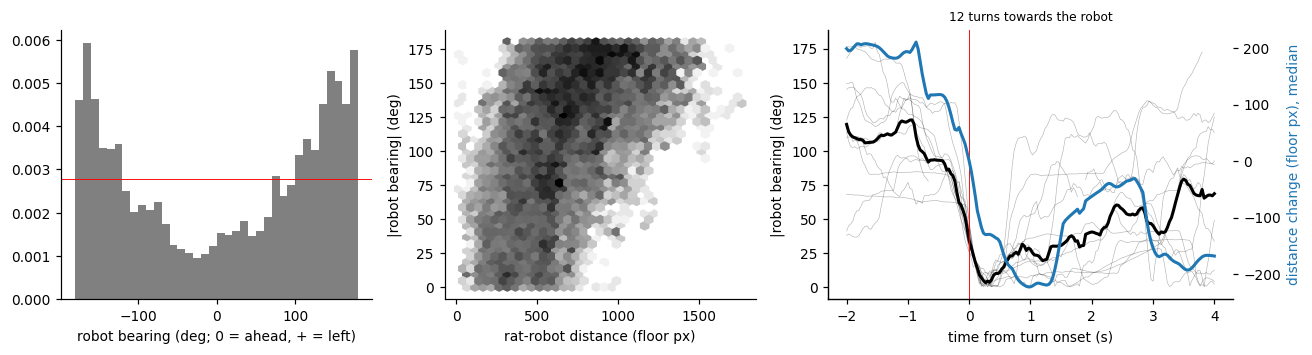

In [13]:
b = pose.robot_bearing.values
okb = ~np.isnan(b) & pose.imu_clean.values
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), gridspec_kw={'width_ratios': [1, 1, 1.3]})
axes[0].hist(b[okb], bins=np.arange(-180, 181, 10), color='grey', density=True); axes[0].axhline(1 / 360, color='r', lw=.6)
axes[0].set_xlabel('robot bearing (deg; 0 = ahead, + = left)')
axes[1].hexbin(pose.robot_distance[okb], np.abs(b[okb]), gridsize=35, cmap='Greys', bins='log')
axes[1].set_xlabel('rat-robot distance (floor px)'); axes[1].set_ylabel('|robot bearing| (deg)')
lag = np.arange(-60, 121)
ev = turns[(turns > 60) & (turns < len(pose) - 121)]
B = np.abs(b[ev[:, None] + lag]); Dd = pose.robot_distance.values[ev[:, None] + lag]; Dd = Dd - Dd[:, [60]]
for row in B:
    axes[2].plot(lag / 30, row, color='k', lw=.4, alpha=.3)
axes[2].plot(lag / 30, np.nanmedian(B, 0), color='k', lw=2)
ax2 = axes[2].twinx(); ax2.plot(lag / 30, np.nanmedian(Dd, 0), color='C0', lw=2); ax2.set_ylabel('distance change (floor px), median', color='C0')
axes[2].axvline(0, color='r', lw=.6); axes[2].set_xlabel('time from turn onset (s)'); axes[2].set_ylabel('|robot bearing| (deg)')
axes[2].set_title(f'{len(ev)} turns towards the robot', fontsize=8)
plt.tight_layout()
print(f'robot within 30 deg of the head direction in {np.mean(np.abs(b[okb]) < 30):.1%} of the frames with a robot bearing '
      f'({okb.mean():.0%} of frames)')

## 5. The session video
The whole session as cam2 video with the head (LED + IMU head direction), the robot centre, the arena from above, dials for robot
bearing / head direction / snout elevation and the movement energy, in 10-minute files. It shows *what* was estimated; sections 3
and 4 show *how certain* it is. Render (from `analysisVR/`, ~5 min on a laptop):

`python scripted_plotting/render_logger_arena_video.py 2026-09-09_15-15_rPG007_P1500_RobotInteract_45min`

/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/rendered_videos/cam2_arena/cam2_arena_00-10min.mp4
/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/rendered_videos/cam2_arena/cam2_arena_10-20min.mp4
/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/rendered_videos/cam2_arena/cam2_arena_20-30min.mp4
/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/rendered_videos/cam2_arena/cam2_arena_30-40min.mp4
/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/RUN_rPG007/rPG007_P1500/2026-09-09_15-15_rPG007_P1500_RobotInteract_45min/rendered_videos/cam2_arena/cam2_arena_40-45min.mp4


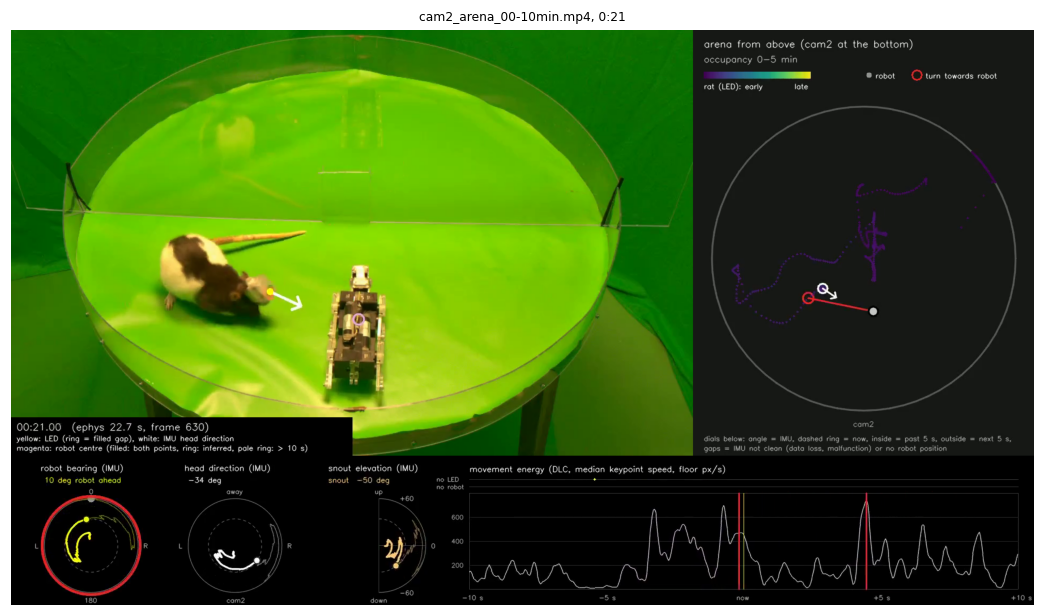

In [14]:
VIDEO_DIR = os.path.join(os.path.dirname(F), 'rendered_videos', 'cam2_arena')
files = sorted(glob.glob(os.path.join(VIDEO_DIR, 'cam2_arena_*min.mp4')))
print('\n'.join(os.path.abspath(f) for f in files) if files else f'not rendered yet: {os.path.abspath(VIDEO_DIR)}')
if files:
    cap = cv2.VideoCapture(files[0]); cap.set(cv2.CAP_PROP_POS_FRAMES, 30 * 21); ok_, frame = cap.read(); cap.release()
    if ok_:
        plt.figure(figsize=(12, 6.8)); plt.imshow(frame[..., ::-1]); plt.axis('off'); plt.title(os.path.basename(files[0]) + ', 0:21', fontsize=8)

## 6. Spikes
`Spikes` has the same columns as the MEA1K sessions and only the curated `single` units. Unreliable periods are their own analytic,
`LoggerMalfunction`, one row per period: `zero_pad` (data replaced by zeros), `zero_pad_margin` (pad ± 30 ms: spike detections are
disturbed around the steps), `logger_window` (logger malfunction window) and `malfunction_period` (the window grown over the
population-rate burst around it, see `logger_session_overview.ipynb` 4a). Spikes in `zero_pad_margin` or `malfunction_period`
(`in_logger_malfunction`) are left out, and the malfunction period is left out of the tuning analyses below.

186 single units, 4,184,336 of 4,365,818 spikes used (95.8%)


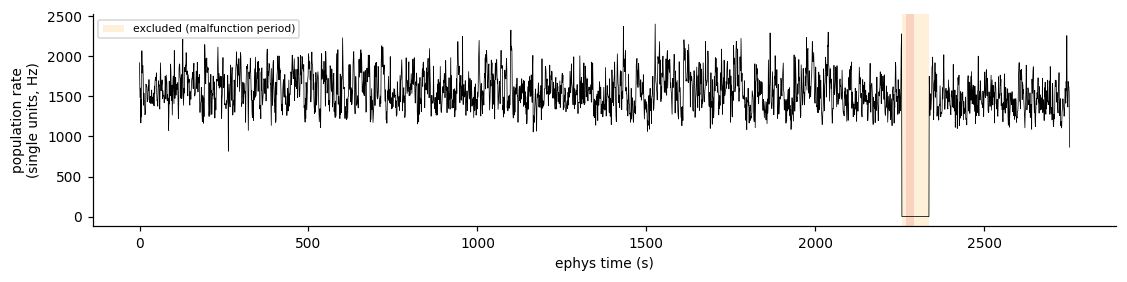

In [15]:
from ephys_preprocessing.postproc_logger_ephys import in_logger_malfunction
single = units.sort_values('cluster_id')                     # Spikes holds single units only
t_spk = spikes.ephys_timestamp.values / 1e6
reliable = ~in_logger_malfunction(spikes.ephys_timestamp.values, data['LoggerMalfunction'])   # pads +-30 ms, malfunction period
use = reliable
print(f'{len(single)} single units, {use.sum():,} of {len(spikes):,} spikes used ({use.mean():.1%})')

rate_1s = pd.Series(use).groupby((t_spk // 1).astype(int)).sum()
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.plot(rate_1s.index, rate_1s.values, color='k', lw=.5); shade(ax)
ax.axvspan(*EXCLUDE, color='orange', alpha=.15, lw=0, label='excluded (malfunction period)')
ax.set_xlabel('ephys time (s)'); ax.set_ylabel('population rate\n(single units, Hz)'); ax.legend(fontsize=7)

## 7. Head-direction tuning
For each single unit: **(1)** the head direction at every spike (the IMU sample at the spike time), **(2)** spike counts per 30° bin
divided by the time spent in that bin = rate (Hz), **(3)** how directional the tuning is: the mean vector length (MVL, 0 = flat,
1 = all spikes in one direction), **(4)** chance level: the same after shifting the spike train against the behaviour by a random
≥ 30 s (200 shifts; a unit counts as tuned above the 99th percentile). Only clean IMU samples and reliable spikes outside the excluded
window are used. `head_direction` is in the cam2 frame (0° = cam2 image right, 90° = away from cam2).

Caveat: the shuffle only tests that the rate depends on the head direction, not why. Head direction goes together with where the rat
is (it spends most time along the walls, facing along them) and what it does, so tuning here is a starting point, not a code.

In [16]:
# shared tuning machinery: spike -> IMU sample, rate per bin, time-shift shuffle
DT = .01                                                     # IMU sample period, s
valid = head.clean.values & ~((t_head >= EXCLUDE[0]) & (t_head < EXCLUDE[1]))
clean_idx = np.flatnonzero(valid)
spk_sample = np.clip(np.searchsorted(head.ephys_timestamp.values, spikes.ephys_timestamp.values[use]), 0, len(head) - 1)
keep = valid[spk_sample]
spk_sample = spk_sample[keep]
unit_row = pd.Series(np.arange(len(single)), index=single.cluster_id.values)[spikes.cluster_id.values[use][keep]].values
spk_pos = np.searchsorted(clean_idx, spk_sample)             # position of each spike among the clean samples
n_units = len(single)

def rates(bin_of_sample, n_bins, sample_of_spike):
    """rate (Hz) per unit and bin; bin_of_sample: bin index per IMU sample (-1 = outside)"""
    occ = np.bincount(bin_of_sample[clean_idx][bin_of_sample[clean_idx] >= 0], minlength=n_bins) * DT
    bs = bin_of_sample[sample_of_spike]; ok_ = bs >= 0
    counts = np.bincount(unit_row[ok_] * n_bins + bs[ok_], minlength=n_units * n_bins).reshape(n_units, n_bins)
    return counts / np.where(occ > 0, occ, np.nan), occ

def shuffled(n=200, seed=0):
    """spike samples after circular shifts of >= 30 s along the clean samples"""
    rng = np.random.default_rng(seed)
    for s in rng.integers(3000, len(clean_idx) - 3000, n):
        yield clean_idx[(spk_pos + s) % len(clean_idx)]

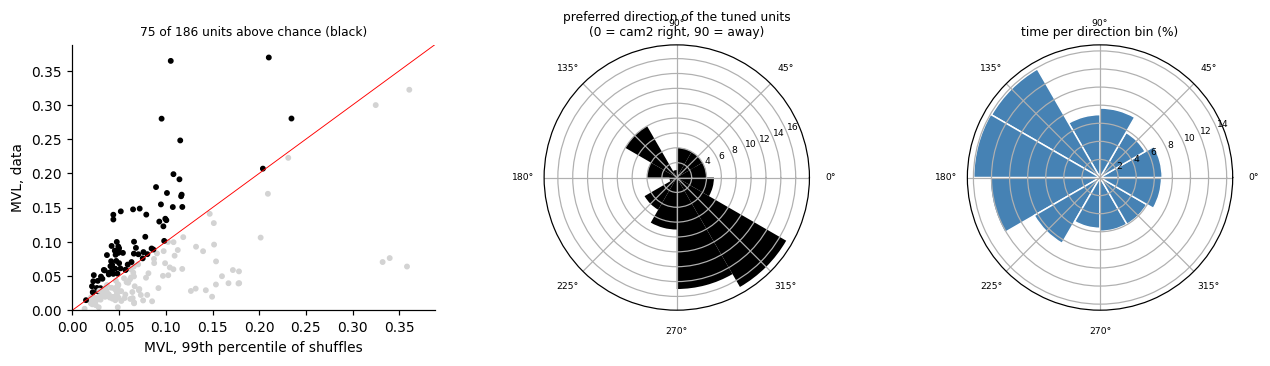

In [17]:
HD_BINS = np.arange(-180, 181, 30)
hd_bin = np.clip(np.digitize(head.head_direction.values, HD_BINS) - 1, 0, len(HD_BINS) - 2)
centres = np.deg2rad(HD_BINS[:-1] + 15)
def mvl(R):
    return np.abs(np.nansum(R * np.exp(1j * centres), 1)) / np.nansum(R, 1)

hd_rate, hd_occ = rates(hd_bin, len(centres), spk_sample)
hd_mvl = mvl(hd_rate)
hd_null = np.array([mvl(rates(hd_bin, len(centres), s)[0]) for s in shuffled()])
hd_p99 = np.nanpercentile(hd_null, 99, axis=0)
hd_tuned = hd_mvl > hd_p99
pref = np.rad2deg(np.angle(np.nansum(hd_rate * np.exp(1j * centres), 1)))

fig = plt.figure(figsize=(12, 3.4))
ax = fig.add_subplot(1, 3, 1)
ax.scatter(hd_p99, hd_mvl, s=8, c=np.where(hd_tuned, 'k', 'lightgrey')); ax.plot([0, 1], [0, 1], color='r', lw=.6)
ax.set_xlim(0, max(hd_p99.max(), hd_mvl.max()) * 1.05); ax.set_ylim(ax.get_xlim())
ax.set_xlabel('MVL, 99th percentile of shuffles'); ax.set_ylabel('MVL, data')
ax.set_title(f'{hd_tuned.sum()} of {n_units} units above chance (black)', fontsize=8)
ax = fig.add_subplot(1, 3, 2, projection='polar')
ax.hist(np.deg2rad(pref[hd_tuned]), bins=12, range=(-np.pi, np.pi), color='k')
ax.set_title('preferred direction of the tuned units\n(0 = cam2 right, 90 = away)', fontsize=8); ax.tick_params(labelsize=6)
ax = fig.add_subplot(1, 3, 3, projection='polar')
ax.bar(centres - np.deg2rad(15), hd_occ / hd_occ.sum() * 100, width=np.deg2rad(30), align='edge', color='steelblue', edgecolor='white')
ax.set_title('time per direction bin (%)', fontsize=8); ax.tick_params(labelsize=6)
plt.tight_layout()

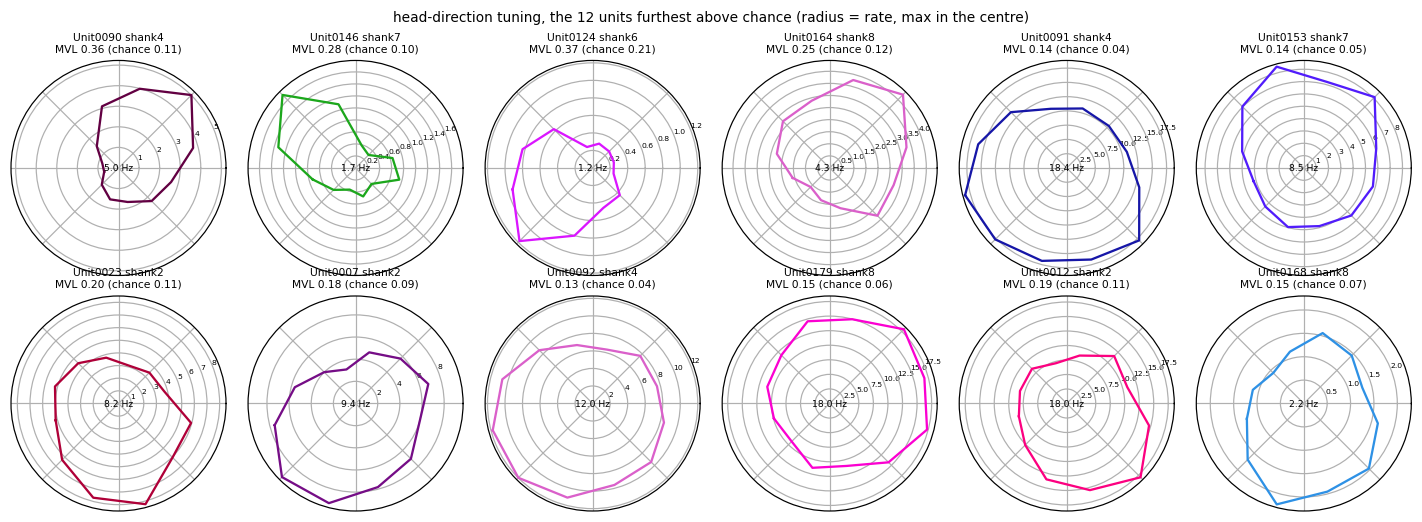

In [18]:
top = np.argsort(-np.nan_to_num(hd_mvl - hd_p99))[:12]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8), subplot_kw={'projection': 'polar'})
for ax, u in zip(axes.ravel(), top):
    r = hd_rate[u]
    ax.plot(np.r_[centres, centres[0]], np.r_[r, r[0]], color=single.cluster_color.iloc[u], lw=1.5)
    ax.set_title(f'{single.cluster_id_str.iloc[u]} {single.shank_name.iloc[u]}\nMVL {hd_mvl[u]:.2f} (chance {hd_p99[u]:.2f})', fontsize=7)
    ax.set_xticklabels([]); ax.tick_params(labelsize=5)
    ax.text(0, 0, f'{np.nanmax(r):.1f} Hz', ha='center', va='center', fontsize=6)
fig.suptitle('head-direction tuning, the 12 units furthest above chance (radius = rate, max in the centre)', fontsize=9)
plt.tight_layout()

## 8. Snout-elevation tuning
The same steps for the snout elevation (10° bins from -70° to +60°, bins with < 5 s are left out). The tuning strength is the
information per spike (bits/spike, Skaggs): 0 = the rate does not depend on the elevation.

Caveat: the snout elevation goes together with behaviour (nose down while sniffing the floor or grooming, nose up when rearing),
and many units fire most with the nose down. Movement or behavioural state can produce this tuning just as well.

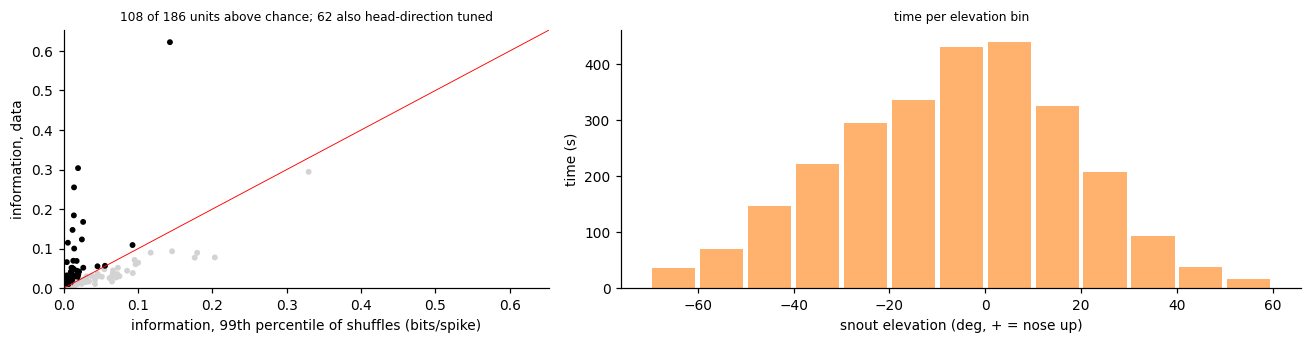

In [19]:
EL_BINS = np.arange(-70, 61, 10)
el_bin = np.digitize(head.snout_elevation.values, EL_BINS) - 1
el_bin[(el_bin < 0) | (el_bin >= len(EL_BINS) - 1)] = -1
el_centres = EL_BINS[:-1] + 5

def info(R, occ):
    ok_ = occ >= 5
    p = occ[ok_] / occ[ok_].sum(); R = R[:, ok_]
    mean = np.nansum(R * p, 1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.nansum(p * (R / mean) * np.log2(np.where(R > 0, R / mean, 1)), 1)

el_rate, el_occ = rates(el_bin, len(el_centres), spk_sample)
el_info = info(el_rate, el_occ)
el_null = np.array([info(rates(el_bin, len(el_centres), s)[0], el_occ) for s in shuffled()])
el_p99 = np.nanpercentile(el_null, 99, axis=0)
el_tuned = el_info > el_p99

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].scatter(el_p99, el_info, s=8, c=np.where(el_tuned, 'k', 'lightgrey')); lim = max(el_p99.max(), el_info.max()) * 1.05
axes[0].plot([0, lim], [0, lim], color='r', lw=.6); axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim)
axes[0].set_xlabel('information, 99th percentile of shuffles (bits/spike)'); axes[0].set_ylabel('information, data')
axes[0].set_title(f'{el_tuned.sum()} of {n_units} units above chance; {np.sum(el_tuned & hd_tuned)} also head-direction tuned', fontsize=8)
axes[1].bar(el_centres, el_occ, width=9, color='C1', alpha=.6); axes[1].set_xlabel('snout elevation (deg, + = nose up)')
axes[1].set_ylabel('time (s)'); axes[1].set_title('time per elevation bin', fontsize=8)
plt.tight_layout()

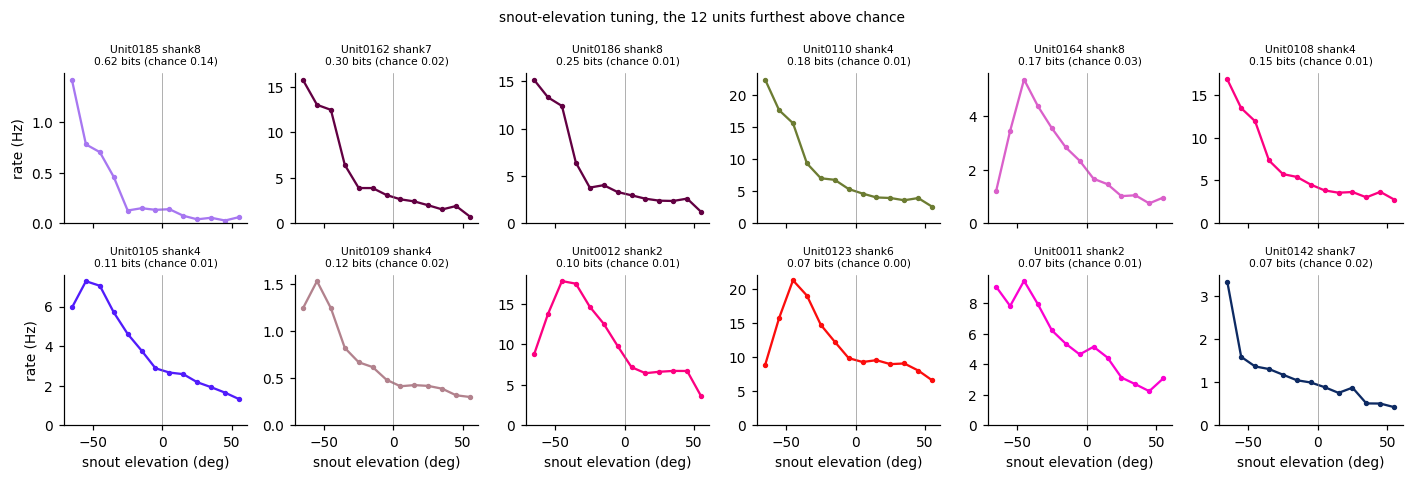

In [20]:
top = np.argsort(-np.nan_to_num(el_info - el_p99))[:12]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.4), sharex=True)
for ax, u in zip(axes.ravel(), top):
    r = np.where(el_occ >= 5, el_rate[u], np.nan)
    ax.plot(el_centres, r, 'o-', ms=2.5, color=single.cluster_color.iloc[u])
    ax.set_title(f'{single.cluster_id_str.iloc[u]} {single.shank_name.iloc[u]}\n{el_info[u]:.2f} bits (chance {el_p99[u]:.2f})', fontsize=7)
    ax.axvline(0, color='grey', lw=.4); ax.set_ylim(0, None)
for ax in axes[1]:
    ax.set_xlabel('snout elevation (deg)')
axes[0, 0].set_ylabel('rate (Hz)'); axes[1, 0].set_ylabel('rate (Hz)')
fig.suptitle('snout-elevation tuning, the 12 units furthest above chance', fontsize=9)
plt.tight_layout()